In [26]:
%pip install gensim

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [27]:
#Import Library

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from gensim.models import Word2Vec, KeyedVectors
from gensim.models.fasttext import FastText
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

In [28]:
import pandas as pd

df = pd.read_csv("../../output/dataset_preprocessed.csv")

text_column = "processed_text"
df = df.dropna(subset=[text_column])

sentences = [
    str(text).split()
    for text in df[text_column]
]

print(f"Jumlah kalimat: {len(sentences)}")
print(f"Contoh kalimat: {sentences[0][:10]}")

Jumlah kalimat: 3353
Contoh kalimat: ['harga', 'emas', 'batang', 'sertifikat', 'antam', 'keluar', 'logam', 'mulia', 'pt', 'aneka']


In [29]:
#Melatih Model Word2Vec

# Latih model Word2Vec
model_w2v = Word2Vec(
    sentences=sentences,
    vector_size=100,    # dimensi embedding
    window=5,           # ukuran konteks kiri-kanan
    min_count=2,        # abaikan kata yang muncul < 2 kali
    workers=4,          # jumlah thread
    epochs=10,          # iterasi training
    sg=1                # 1 = Skip-gram, 0 = CBOW
)

print("Model Word2Vec berhasil dilatih.")
print(f"Ukuran vocabulary: {len(model_w2v.wv)}")

Model Word2Vec berhasil dilatih.
Ukuran vocabulary: 11055


In [30]:
# Simpan model
model_w2v.save("word2vec_model.bin")

# Load model
# model_w2v = Word2Vec.load("word2vec_model.bin")

In [31]:
#Melihat Vektor Kata

# Contoh kata dari dataset
sample_word = "bagus"

if sample_word in model_w2v.wv:
    vector = model_w2v.wv[sample_word]
    print(f"Vektor '{sample_word}':")
    print(f"  Dimensi : {vector.shape}")
    print(f"  Nilai   : {vector[:10]}...")  # tampilkan 10 dimensi pertama
else:
    print(f"Kata '{sample_word}' tidak ada dalam vocabulary.")

Vektor 'bagus':
  Dimensi : (100,)
  Nilai   : [ 0.01006794  0.22652155 -0.15163733 -0.18824503 -0.16061674  0.11890088
 -0.10900111  0.2936169  -0.6215916   0.84155804]...


In [32]:
#Mencari Kata Paling Mirip

def find_similar_words(word, model, top_n=10):
    if word not in model.wv:
        print(f"Kata '{word}' tidak ada dalam vocabulary.")
        return []
    similar = model.wv.most_similar(word, topn=top_n)
    return similar

# Contoh
test_words = ["bagus", "buruk", "hotel", "pelayanan"]

for word in test_words:
    print(f"\nKata yang mirip dengan '{word}':")
    similar = find_similar_words(word, model_w2v)
    for similar_word, score in similar:
        print(f"  {similar_word:<20} : {score:.4f}")


Kata yang mirip dengan 'bagus':
  serok                : 0.6550
  buram                : 0.6317
  visibility           : 0.6313
  jendela              : 0.6168
  screening            : 0.6053
  catch                : 0.6026
  commit               : 0.6007
  lihat                : 0.5999
  story                : 0.5954
  kerucut              : 0.5953

Kata yang mirip dengan 'buruk':
  hantu                : 0.6691
  resesi               : 0.6478
  tekan                : 0.6459
  latuhihin            : 0.6329
  zandi                : 0.6212
  picu                 : 0.6171
  stagflasi            : 0.6159
  cerna                : 0.6140
  reyot                : 0.6123
  mogok                : 0.6119

Kata yang mirip dengan 'hotel':
  mall                 : 0.6466
  pullman              : 0.6420
  destinasi            : 0.6216
  apartemen            : 0.6205
  regent               : 0.6157
  hills                : 0.6155
  vimala               : 0.6111
  kempinski            : 0.6079
  res

In [33]:
#Similarity Antar Kata

def word_similarity(word1, word2, model):
    if word1 not in model.wv or word2 not in model.wv:
        return None
    return model.wv.similarity(word1, word2)

# Uji beberapa pasangan kata
pairs = [
    ("bagus", "baik"),
    ("bagus", "buruk"),
    ("hotel", "penginapan"),
    ("hotel", "mobil"),
]

print("Similarity antar kata:")
print("-" * 40)
for w1, w2 in pairs:
    sim = word_similarity(w1, w2, model_w2v)
    if sim is not None:
        print(f"  {w1} ↔ {w2:<20}: {sim:.4f}")

Similarity antar kata:
----------------------------------------
  bagus ↔ baik                : 0.4733
  bagus ↔ buruk               : 0.2722
  hotel ↔ mobil               : 0.2045


In [34]:
#Operasi Vektor Kata

# Cari kata yang paling mendekati: positif - negatif + ...
try:
    result = model_w2v.wv.most_similar(
        positive=["bagus", "pelayanan"],
        negative=["buruk"],
        topn=5
    )
    print("Hasil operasi vektor:")
    for word, score in result:
        print(f"  {word:<20} : {score:.4f}")
except Exception as e:
    print(f"Error: {e}")
    print("Pastikan kata-kata tersebut ada dalam vocabulary.")

Error: "Key 'pelayanan' not present in vocabulary"
Pastikan kata-kata tersebut ada dalam vocabulary.


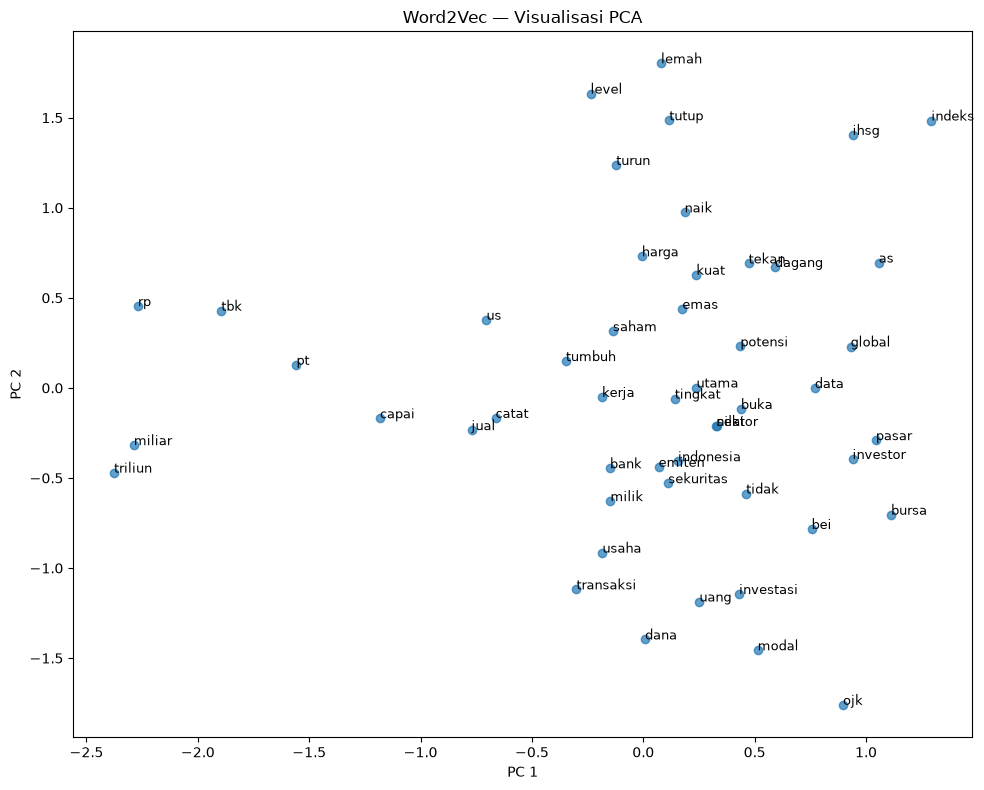

In [35]:
#Visualisasi dengan PCA

def visualize_embeddings_pca(words, model, title="Word Embedding PCA"):
    # Filter kata yang ada dalam vocabulary
    valid_words = [w for w in words if w in model.wv]
    if not valid_words:
        print("Tidak ada kata yang tersedia dalam vocabulary.")
        return

    vectors = np.array([model.wv[w] for w in valid_words])

    # Reduksi ke 2D dengan PCA
    pca = PCA(n_components=2)
    vectors_2d = pca.fit_transform(vectors)

    plt.figure(figsize=(10, 8))
    plt.scatter(vectors_2d[:, 0], vectors_2d[:, 1], alpha=0.7)
    for i, word in enumerate(valid_words):
        plt.annotate(
            word,
            xy=(vectors_2d[i, 0], vectors_2d[i, 1]),
            fontsize=9
        )
    plt.title(title)
    plt.xlabel("PC 1")
    plt.ylabel("PC 2")
    plt.tight_layout()
    plt.show()

# Ambil top 50 kata paling sering
top_words = [word for word, _ in model_w2v.wv.key_to_index.items()][:50]
visualize_embeddings_pca(top_words, model_w2v, "Word2Vec — Visualisasi PCA")

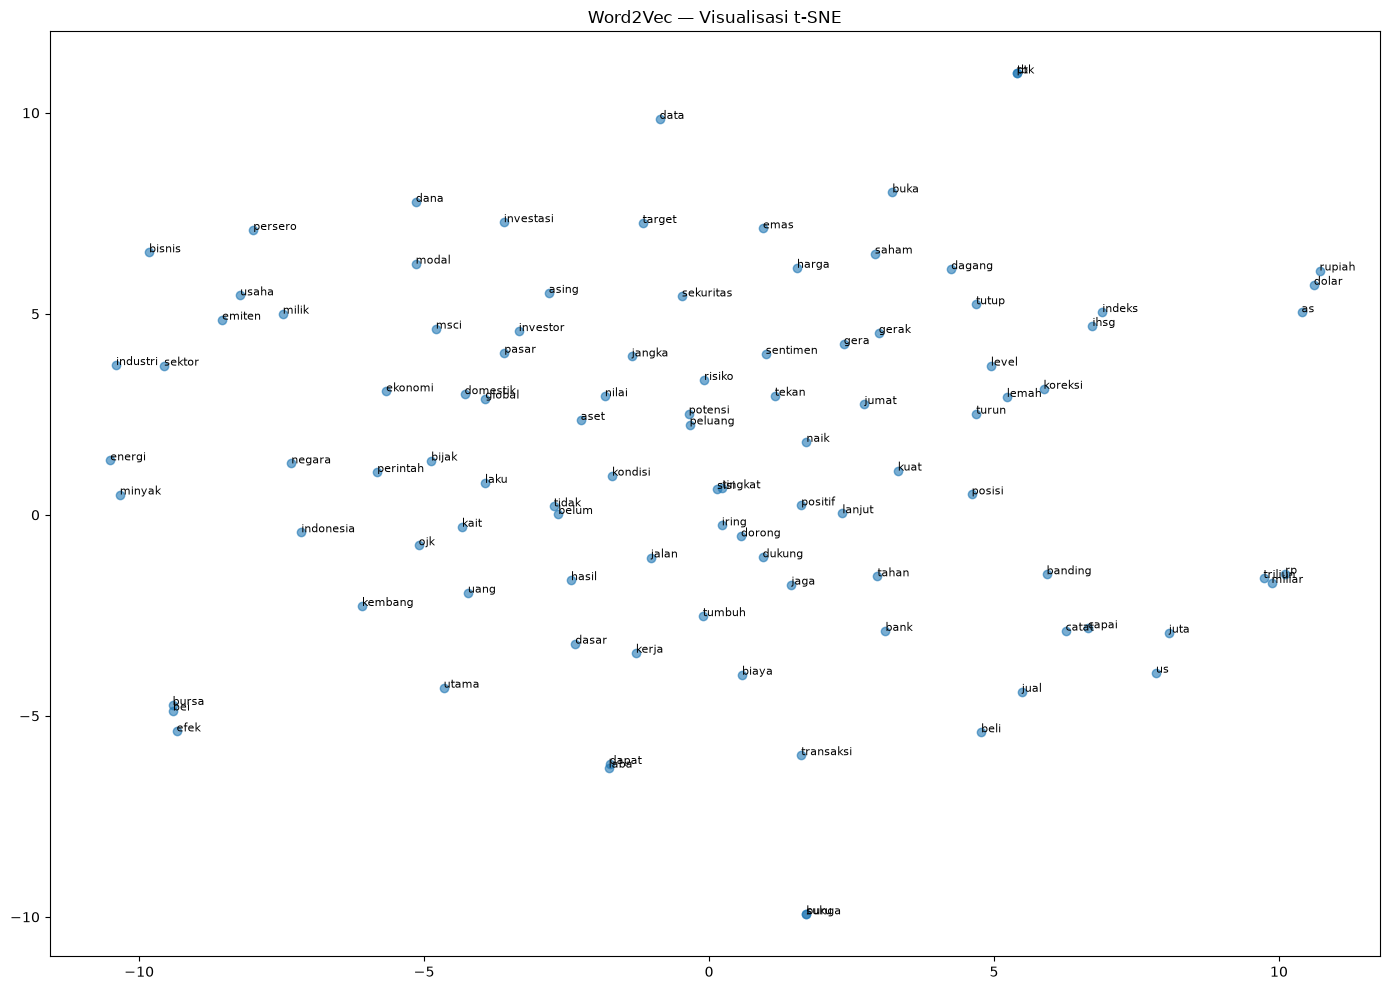

In [36]:

# Visualisasi dengan t-SNE

def visualize_embeddings_tsne(words, model, title="Word Embedding t-SNE"):
    valid_words = [w for w in words if w in model.wv]

    if len(valid_words) < 10:
        print("Terlalu sedikit kata untuk t-SNE.")
        return

    vectors = np.array([model.wv[w] for w in valid_words])

    # Perbaikan: n_iter diganti menjadi max_iter
    tsne = TSNE(
        n_components=2,
        perplexity=15,
        random_state=42,
        max_iter=1000
    )

    vectors_2d = tsne.fit_transform(vectors)

    plt.figure(figsize=(14, 10))
    plt.scatter(vectors_2d[:, 0], vectors_2d[:, 1], alpha=0.6)

    for i, word in enumerate(valid_words):
        plt.annotate(
            word,
            xy=(vectors_2d[i, 0], vectors_2d[i, 1]),
            fontsize=8
        )

    plt.title(title)
    plt.tight_layout()
    plt.show()


top_words = list(model_w2v.wv.key_to_index.keys())[:100]

visualize_embeddings_tsne(
    top_words,
    model_w2v,
    "Word2Vec — Visualisasi t-SNE"
)


In [37]:
#FastText (Menangani OOV)

# Latih model FastText
model_ft = FastText(
    sentences=sentences,
    vector_size=100,
    window=5,
    min_count=2,
    workers=4,
    epochs=10
)

# FastText dapat menangani kata baru (OOV)
oov_word = "ketidakberhasilannya"  # kata yang mungkin tidak ada di corpus
vector_oov = model_ft.wv[oov_word]
print(f"FastText berhasil menghasilkan vektor untuk '{oov_word}'")
print(f"Dimensi: {vector_oov.shape}")

FastText berhasil menghasilkan vektor untuk 'ketidakberhasilannya'
Dimensi: (100,)


In [38]:
#Perbandingan Word2Vec vs FastText

test_oov = "pemrogramannya"  # kata dengan imbuhan kompleks

print("Perbandingan Word2Vec vs FastText:")
print("-" * 50)

if test_oov in model_w2v.wv:
    w2v_similar = model_w2v.wv.most_similar(test_oov, topn=5)
    print(f"\nWord2Vec — '{test_oov}':")
    for w, s in w2v_similar:
        print(f"  {w:<20}: {s:.4f}")
else:
    print(f"\nWord2Vec: '{test_oov}' tidak ada dalam vocabulary (OOV)")

ft_similar = model_ft.wv.most_similar(test_oov, topn=5)
print(f"\nFastText — '{test_oov}':")
for w, s in ft_similar:
    print(f"  {w:<20}: {s:.4f}")

Perbandingan Word2Vec vs FastText:
--------------------------------------------------

Word2Vec: 'pemrogramannya' tidak ada dalam vocabulary (OOV)

FastText — 'pemrogramannya':
  program             : 0.8004
  pemuda              : 0.7100
  demografi           : 0.6620
  mudharabah          : 0.6361
  gizi                : 0.6098


## F. Tugas Analisis

In [39]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from gensim.models import Word2Vec, FastText
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans

sentences = [t.split() for t in df["processed_text"]]
print("Jumlah dokumen:", len(sentences))
print("Jumlah token  :", sum(len(s) for s in sentences))

PARAMS = dict(vector_size=100, window=5, min_count=5, workers=4, epochs=30, seed=42)

w2v_cbow = Word2Vec(sentences, sg=0, **PARAMS)                      # CBOW
w2v_sg   = Word2Vec(sentences, sg=1, **PARAMS)                      # Skip-gram
ft_model = FastText(sentences, sg=1, min_n=3, max_n=6, **PARAMS)    # FastText

print("Vocabulary Word2Vec:", len(w2v_cbow.wv))
print("Vocabulary FastText:", len(ft_model.wv))

Jumlah dokumen: 3353
Jumlah token  : 777758
Vocabulary Word2Vec: 6603
Vocabulary FastText: 6603


In [40]:
# Tugas 1. CBOW (sg=0) vs Skip-gram (sg=1)
kata_uji = ["rupiah", "saham", "emas", "bank", "naik", "investor"]
kata_uji = [k for k in kata_uji if k in w2v_cbow.wv]

for k in kata_uji:
    c = w2v_cbow.wv.most_similar(k, topn=8)
    s = w2v_sg.wv.most_similar(k, topn=8)
    print(f"=== {k} ===")
    print("CBOW      :", ", ".join(f"{w} ({x:.2f})" for w, x in c))
    print("Skip-gram :", ", ".join(f"{w} ({x:.2f})" for w, x in s))
    print("Irisan    :", len({w for w, _ in c} & {w for w, _ in s}), "kata\n")


=== rupiah ===
CBOW      : dolar (0.58), kurs (0.50), ihsg (0.46), inflasi (0.44), josua (0.43), psikologis (0.42), bi (0.42), tukar (0.41)
Skip-gram : tukar (0.78), dolar (0.73), kurs (0.65), jisdor (0.59), ndf (0.59), hareva (0.58), bi (0.58), taufan (0.58)
Irisan    : 4 kata

=== saham ===
CBOW      : bbca (0.58), emiten (0.51), ihsg (0.50), kapital (0.50), bmri (0.47), lembar (0.47), tlkm (0.46), indeks (0.46)
Skip-gram : bbca (0.66), bmri (0.63), sungkur (0.59), bbni (0.59), emtk (0.58), sekar (0.58), kapital (0.57), mahar (0.57)
Irisan    : 3 kata

=== emas ===
CBOW      : tembaga (0.61), troi (0.55), perak (0.54), ons (0.53), nikel (0.51), silver (0.49), troy (0.48), platinum (0.47)
Skip-gram : perak (0.70), mulia (0.67), ons (0.65), logam (0.64), ounces (0.64), troi (0.62), gram (0.61), ounce (0.60)
Irisan    : 3 kata

=== bank ===
CBOW      : perban (0.44), bbri (0.39), bmri (0.39), kustodian (0.36), btps (0.36), kredit (0.36), bbni (0.35), telkom (0.34)
Skip-gram : rakyat (0.

In [41]:
# Tugas 2. Lima pasang kata yang mirip

pasangan = [("naik", "melonjak"), ("turun", "anjlok"), ("rupiah", "dolar"),
            ("saham", "emiten"), ("laba", "pendapatan"), ("ihsg", "indeks")]

baris = []
for a, b in pasangan:
    if a in w2v_sg.wv and b in w2v_sg.wv:
        baris.append({"kata 1": a, "kata 2": b,
                      "CBOW": w2v_cbow.wv.similarity(a, b),
                      "Skip-gram": w2v_sg.wv.similarity(a, b),
                      "FastText": ft_model.wv.similarity(a, b)})
    else:
        print(f"Dilewati (di luar vocabulary): {a}, {b}")
print(pd.DataFrame(baris).round(3).to_string(index=False))

# Pembanding: rata-rata similarity pasangan kata acak
rng = np.random.default_rng(42)
kosa = w2v_sg.wv.index_to_key
acak = [w2v_sg.wv.similarity(*rng.choice(kosa, 2, replace=False)) for _ in range(1000)]
print(f"\nRata-rata similarity pasangan acak: {np.mean(acak):.3f}")


Dilewati (di luar vocabulary): naik, melonjak
Dilewati (di luar vocabulary): laba, pendapatan
kata 1 kata 2  CBOW  Skip-gram  FastText
 turun anjlok 0.656      0.690     0.662
rupiah  dolar 0.583      0.731     0.743
 saham emiten 0.507      0.477     0.472
  ihsg indeks 0.638      0.681     0.654

Rata-rata similarity pasangan acak: 0.184


In [42]:
# Tugas 3. Operasi vektor

def analogi(positif, negatif=None, model=w2v_sg, topn=5):
    negatif = negatif or []
    oov = [k for k in positif + negatif if k not in model.wv]
    if oov:
        print(f"Dilewati, di luar vocabulary: {oov}\n")
        return
    hasil = model.wv.most_similar(positive=positif, negative=negatif, topn=topn)
    ekspresi = " + ".join(positif) + "".join(f" - {n}" for n in negatif)
    print(f"{ekspresi}  =>  " + ", ".join(f"{w} ({s:.2f})" for w, s in hasil) + "\n")

analogi(["rupiah", "amerika"], ["indonesia"])
analogi(["dolar", "indonesia"], ["amerika"])
analogi(["bank", "sentral"])
analogi(["naik", "melemah"], ["turun"])
analogi(["saham", "bank"], ["emas"])
analogi(["jepang", "yen"], ["amerika"])

rupiah + amerika - indonesia  =>  as (0.71), serikat (0.70), dolar (0.63), ibrahim (0.54), tegang (0.54)

dolar + indonesia - amerika  =>  mata (0.45), jisdor (0.43), idaa (0.41), peso (0.41), nobu (0.41)

bank + sentral  =>  european (0.66), england (0.58), cook (0.56), moneter (0.56), minutes (0.56)

Dilewati, di luar vocabulary: ['melemah']

saham + bank - emas  =>  bmri (0.56), bbri (0.53), bbca (0.53), bbni (0.52), arta (0.49)

jepang + yen - amerika  =>  won (0.59), rupee (0.56), jpy (0.55), ringgit (0.51), nikkei (0.50)



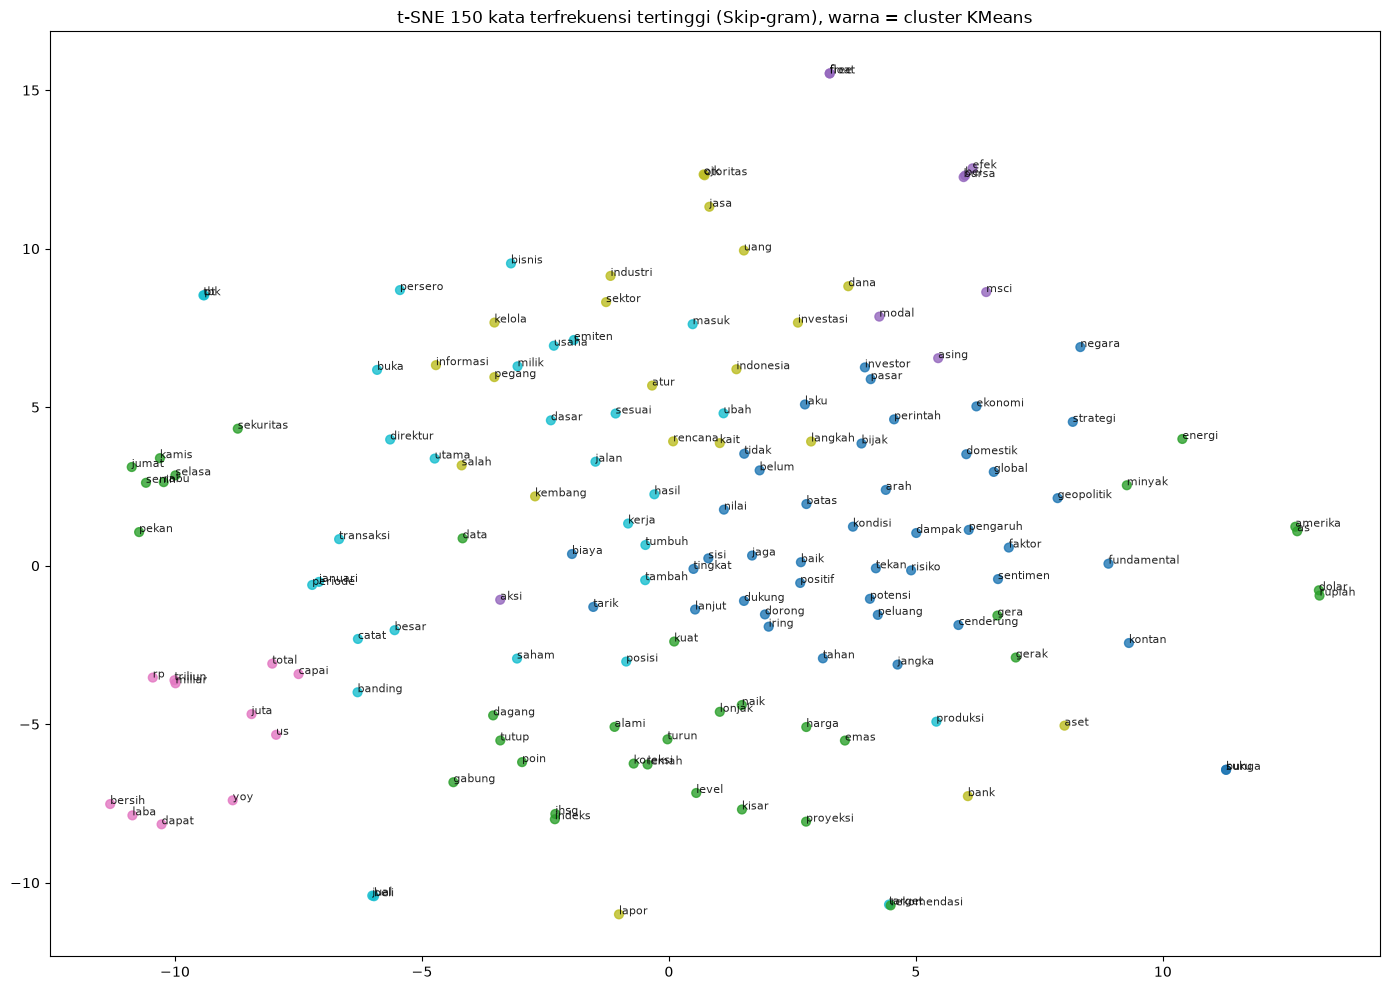

Cluster 0: pasar, nilai, investor, tingkat, tidak, global, potensi, tekan, bijak, dorong, jangka, lanjut, ekonomi, sentimen, risiko, sisi, kondisi, bunga, laku, dukung, perintah, negara, tahan, suku, biaya, positif, domestik, peluang, belum, jaga, iring, batas, dampak, fundamental, cenderung, strategi, kontan, tarik, baik, geopolitik, arah, pengaruh, faktor
Cluster 1: harga, kuat, level, turun, ihsg, dagang, indeks, lemah, as, emas, data, naik, sekuritas, tutup, energi, rupiah, gerak, gera, koreksi, jumat, minyak, dolar, pekan, alami, rabu, gabung, senin, kamis, lonjak, proyeksi, rekomendasi, poin, selasa, amerika, kisar
Cluster 2: modal, bursa, bei, efek, asing, msci, free, float, aksi
Cluster 3: rp, triliun, miliar, us, capai, juta, dapat, laba, bersih, total, yoy
Cluster 4: indonesia, uang, bank, sektor, ojk, dana, investasi, aset, kait, kembang, industri, lapor, rencana, jasa, kelola, atur, informasi, salah, pegang, langkah, otoritas
Cluster 5: saham, pt, tbk, usaha, milik, catat, 

In [43]:
# Tugas 4. Visualisasi embedding dan cluster

N = 150
kata = w2v_sg.wv.index_to_key[:N]
X = np.array([w2v_sg.wv[k] for k in kata])

xy = TSNE(n_components=2, perplexity=20, random_state=42, init="pca").fit_transform(X)
labels = KMeans(n_clusters=6, random_state=42, n_init=10).fit_predict(X)

plt.figure(figsize=(14, 10))
plt.scatter(xy[:, 0], xy[:, 1], c=labels, cmap="tab10", s=40, alpha=0.8)
for (x, y), k in zip(xy, kata):
    plt.annotate(k, (x, y), fontsize=8, alpha=0.85)
plt.title("t-SNE 150 kata terfrekuensi tertinggi (Skip-gram), warna = cluster KMeans")
plt.tight_layout()
plt.show()

for c in range(6):
    print(f"Cluster {c}:", ", ".join(k for k, l in zip(kata, labels) if l == c))

In [44]:
# Tugas 5. Word2Vec vs FastText pada kata berimbuhan

uji = ["penguatan", "pelemahan", "menguat", "melemah", "memperkuat",
       "terkoreksinya", "pelemahannya", "menguatnya", "kenaikannya", "penurunannya"]

print(f"{'kata':<16}{'ada di vocab W2V?':<20}FastText: tetangga terdekat")
for k in uji:
    ft = ", ".join(w for w, _ in ft_model.wv.most_similar(k, topn=5))
    print(f"{k:<16}{str(k in w2v_sg.wv):<20}{ft}")

print("\nWord2Vec pada kata di luar vocabulary:")
for k in uji:
    if k not in w2v_sg.wv:
        try:
            w2v_sg.wv[k]
        except KeyError:
            print(f"  {k}: KeyError (tidak punya vektor)")
            break

print("\nSimilarity kata berimbuhan dengan kata dasarnya:")
for a, b in [("menguat", "penguatan"), ("melemah", "pelemahan"),
             ("naik", "kenaikan"), ("turun", "penurunan")]:
    w = f"{w2v_sg.wv.similarity(a, b):.3f}" if a in w2v_sg.wv and b in w2v_sg.wv else "OOV"
    print(f"  {a:<10}{b:<12} Word2Vec: {w:<7} FastText: {ft_model.wv.similarity(a, b):.3f}")

kata            ada di vocab W2V?   FastText: tetangga terdekat
penguatan       False               peng, cempaka, kav, sengsara, pim
pelemahan       False               telematika, nonprimer, idxnoncyc, idxindust, idxtechno
menguat         False               hamengkubuwono, kontroversial, scotus, spanyol, persis
melemah         False               lemah, telematika, meleset, koreksi, tekan
memperkuat      False               mempertanggungjawabkan, mem, carlton, ampera, saking
terkoreksinya   False               koreksi, valuasinya, rebound, positive, sinyalir
pelemahannya    False               rinciannya, bahwasannya, telematika, triliunpt, fanny
menguatnya      False               hamengkubuwono, persis, owl, shib, greed
kenaikannya     False               rinciannya, bahwasannya, twinwood, jt, smdm
penurunannya    False               rinciannya, bahwasannya, lbre, agio, uupm

Word2Vec pada kata di luar vocabulary:
  penguatan: KeyError (tidak punya vektor)

Similarity kata berimb